In [1]:
# figures for the report, all built from the saved results files
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE = '/content/drive/MyDrive/Colab Notebooks/Machine Learning/Assignment 4/'
RESULTS_DIR = BASE + 'results/'
FIG_DIR = BASE + 'figures/'

# one colour per model, used in every figure, plus a hatch so the bars still differ in a greyscale print
COLOURS = {'knn': '#2a78d6', 'tree': '#eb6834', 'forest': '#1baf7a'}
HATCHES = {'knn': '//', 'tree': '..', 'forest': ''}
NAMES = {'knn': 'kNN', 'tree': 'Tree', 'forest': 'Forest'}
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e1e0d9'

plt.rcParams.update({'font.size': 8, 'axes.titlesize': 8, 'axes.labelsize': 8, 'xtick.labelsize': 7,
                     'ytick.labelsize': 7, 'legend.fontsize': 7, 'font.family': 'serif',
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
                     'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
                     'lines.linewidth': 1.5, 'lines.markersize': 4, 'savefig.dpi': 300, 'savefig.bbox': 'tight'})
COL_W, PAGE_W = 3.5, 7.16   # IEEE single column and full page width in inches

def save(fig, name):
    # pdf for the report, png for a quick look
    fig.savefig(FIG_DIR + name + '.pdf')
    fig.savefig(FIG_DIR + name + '.png')
    plt.show()

log = pd.read_csv(RESULTS_DIR + 'rf_experiments.csv')
print(len(log), "rows in the experiment log")

def setting_stats(settings):
    s = log[log['setting'].isin(settings)].groupby('setting')['macro_f1'].agg(['mean', 'std'])
    return s.loc[settings]

Mounted at /content/drive
165 rows in the experiment log


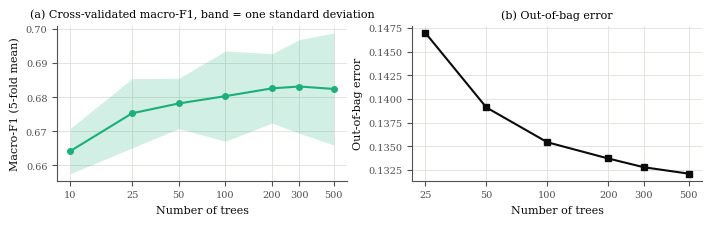

In [ ]:
# figure 1 - macro-F1 and out-of-bag error against the number of trees
# two panels, because the two measures are on different scales
e1 = pd.read_csv(RESULTS_DIR + 'rf_e1_trees.csv').groupby('n_estimators')['macro_f1'].agg(['mean', 'std'])
oob = pd.read_csv(RESULTS_DIR + 'rf_e1_oob.csv')

fig, axes = plt.subplots(1, 2, figsize=(PAGE_W, 2.3))
ax = axes[0]
ax.fill_between(e1.index, e1['mean'] - e1['std'], e1['mean'] + e1['std'], color=COLOURS['forest'], alpha=0.2, linewidth=0)
ax.plot(e1.index, e1['mean'], marker='o', color=COLOURS['forest'])
ax.set_xscale('log')
ax.set_xticks(e1.index); ax.set_xticklabels(e1.index); ax.minorticks_off()
ax.set_xlabel('Number of trees'); ax.set_ylabel('Macro-F1 (5-fold mean)')
ax.set_title('(a) Cross-validated macro-F1, band = one standard deviation')

ax = axes[1]
ax.plot(oob['n_estimators'], oob['oob_error'], marker='s', color=INK)
ax.set_xscale('log')
ax.set_xticks(oob['n_estimators']); ax.set_xticklabels(oob['n_estimators']); ax.minorticks_off()
ax.set_xlabel('Number of trees'); ax.set_ylabel('Out-of-bag error')
ax.set_title('(b) Out-of-bag error')
fig.tight_layout()
save(fig, 'fig1_number_of_trees')

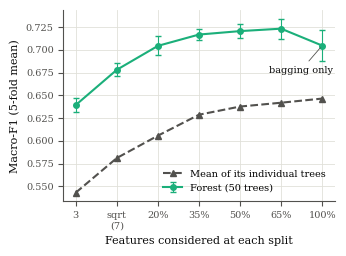

In [ ]:
# figure 2 - forest macro-F1 and the average macro-F1 of its individual trees,
# against the number of features considered at each split
mf_settings = ['max_features=3', 'max_features=sqrt', 'max_features=0.2', 'max_features=0.35',
               'max_features=0.5', 'max_features=0.65', 'max_features=1.0']
mf_x = list(range(len(mf_settings)))   # evenly spaced, the values are in the tick labels
mf_labels = ['3', 'sqrt\n(7)', '20%', '35%', '50%', '65%', '100%']
forest_f1 = setting_stats(mf_settings)
tree_f1 = log[log['setting'].isin(mf_settings)].groupby('setting')['mean_tree_f1'].mean().loc[mf_settings]

fig, ax = plt.subplots(figsize=(COL_W, 2.6))
ax.errorbar(mf_x, forest_f1['mean'], yerr=forest_f1['std'], marker='o', color=COLOURS['forest'],
            capsize=2, elinewidth=0.8, label='Forest (50 trees)')
ax.plot(mf_x, tree_f1.values, marker='^', linestyle='--', color=MUTED, label='Mean of its individual trees')
ax.set_xticks(mf_x); ax.set_xticklabels(mf_labels)
ax.set_xlabel('Features considered at each split'); ax.set_ylabel('Macro-F1 (5-fold mean)')
ax.annotate('bagging only', xy=(mf_x[-1], forest_f1['mean'].iloc[-1]),
            xytext=(mf_x[-1] - 1.3, forest_f1['mean'].iloc[-1] - 0.03),
            fontsize=7, color=INK, arrowprops={'arrowstyle': '-', 'color': MUTED, 'linewidth': 0.6})
ax.legend(frameon=False, loc='lower right')
fig.tight_layout()
save(fig, 'fig2_feature_randomness')

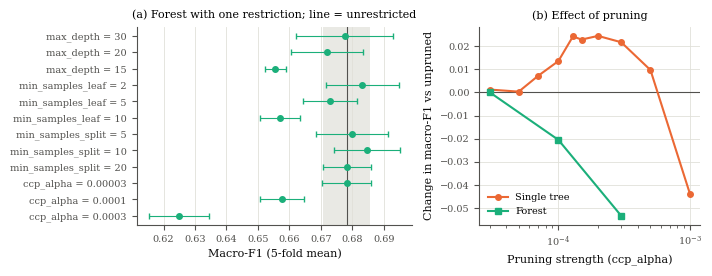

In [ ]:
# figure 3 - (a) the forest with one restriction at a time against the unrestricted forest
#            (b) the same pruning applied to the single tree and to the forest
e4_settings = ['max_depth=30', 'max_depth=20', 'max_depth=15', 'min_samples_leaf=2', 'min_samples_leaf=5',
               'min_samples_leaf=10', 'min_samples_split=5', 'min_samples_split=10', 'min_samples_split=20',
               'ccp_alpha=0.00003', 'ccp_alpha=0.0001', 'ccp_alpha=0.0003']
e4 = setting_stats(e4_settings)
ref = setting_stats(['max_features=sqrt']).iloc[0]
tree_alpha = pd.read_csv(RESULTS_DIR + 'tree_ccp_alpha.csv').groupby('ccp_alpha')['macro_f1'].mean()

fig, axes = plt.subplots(1, 2, figsize=(PAGE_W, 2.8), gridspec_kw={'width_ratios': [1.25, 1]})
ax = axes[0]
y = np.arange(len(e4_settings))[::-1]
ax.axvspan(ref['mean'] - ref['std'], ref['mean'] + ref['std'], color=GRID, alpha=0.7, linewidth=0)
ax.axvline(ref['mean'], color=MUTED, linewidth=0.8)
ax.errorbar(e4['mean'], y, xerr=e4['std'], fmt='o', color=COLOURS['forest'], capsize=2, elinewidth=0.8)
ax.set_yticks(y); ax.set_yticklabels([s.replace('=', ' = ') for s in e4_settings])
ax.set_xlabel('Macro-F1 (5-fold mean)')
ax.set_title('(a) Forest with one restriction; line = unrestricted')
ax.grid(axis='y', visible=False)

# change from the unpruned model, so the tree and the forest can share one axis
ax = axes[1]
tree_change = tree_alpha[tree_alpha.index > 0] - tree_alpha.loc[0]
forest_alpha = [0.00003, 0.0001, 0.0003]
forest_change = [e4.loc[f'ccp_alpha={a}', 'mean'] - ref['mean'] for a in ['0.00003', '0.0001', '0.0003']]
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.plot(tree_change.index, tree_change.values, marker='o', color=COLOURS['tree'], label='Single tree')
ax.plot(forest_alpha, forest_change, marker='s', color=COLOURS['forest'], label='Forest')
ax.set_xscale('log')
ax.set_xlabel('Pruning strength (ccp_alpha)'); ax.set_ylabel('Change in macro-F1 vs unpruned')
ax.set_title('(b) Effect of pruning')
ax.legend(frameon=False, loc='lower left')
fig.tight_layout()
save(fig, 'fig3_tree_complexity')

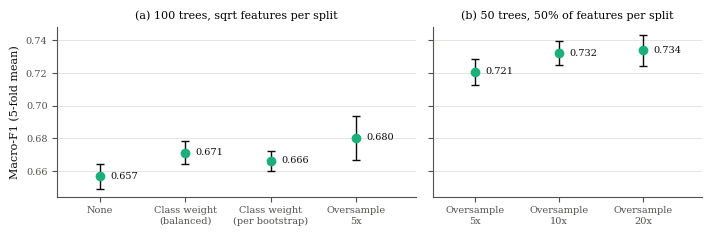

In [ ]:
# figure 4 - imbalance strategies
# two panels because the two sets of runs used different forest settings and are not comparable with each other
a_settings = ['no correction', 'class_weight balanced', 'class_weight balanced_subsample', 'default forest']
a_labels = ['None', 'Class weight\n(balanced)', 'Class weight\n(per bootstrap)', 'Oversample\n5x']
b_settings = ['max_features=0.5', 'oversampling 10x, max_features=0.5', 'oversampling 20x, max_features=0.5']
b_labels = ['Oversample\n5x', 'Oversample\n10x', 'Oversample\n20x']
a, b = setting_stats(a_settings), setting_stats(b_settings)

fig, axes = plt.subplots(1, 2, figsize=(PAGE_W, 2.4), gridspec_kw={'width_ratios': [4, 3]}, sharey=True)
for ax, s, labels, title in [(axes[0], a, a_labels, '(a) 100 trees, sqrt features per split'),
                             (axes[1], b, b_labels, '(b) 50 trees, 50% of features per split')]:
    ax.errorbar(range(len(s)), s['mean'], yerr=s['std'], fmt='o', color=COLOURS['forest'], markersize=6,
                capsize=3, elinewidth=1, ecolor=INK)
    for i, v in enumerate(s['mean']):
        ax.text(i + 0.12, v, f'{v:.3f}', ha='left', va='center', fontsize=7, color=INK)
    ax.set_xticks(range(len(s))); ax.set_xticklabels(labels)
    ax.set_xlim(-0.5, len(s) - 0.3)
    ax.set_title(title); ax.grid(axis='x', visible=False)
axes[0].set_ylabel('Macro-F1 (5-fold mean)')
fig.tight_layout()
save(fig, 'fig4_imbalance')

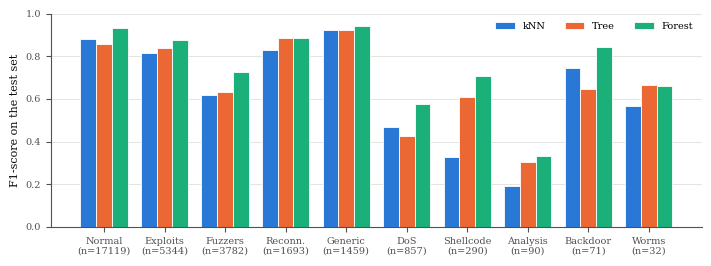

In [ ]:
# figure 5 - F1 per class on the test set for the three models, classes ordered by size
pc = pd.read_csv(RESULTS_DIR + 'final_test_per_class.csv', index_col=0)
pc = pc.sort_values('support', ascending=False)
models = ['knn', 'tree', 'forest']

fig, ax = plt.subplots(figsize=(PAGE_W, 2.7))
x = np.arange(len(pc)); width = 0.26
for i, m in enumerate(models):
    ax.bar(x + (i - 1) * width, pc[m], width=width, color=COLOURS[m],
           edgecolor='white', linewidth=0.6, label=NAMES[m])
ax.set_xticks(x)
ax.set_xticklabels([f'{name}\n(n={int(n)})' for name, n in
                    zip(pc.index.str.replace('Reconnaissance', 'Reconn.'), pc['support'])])
ax.set_ylabel('F1-score on the test set'); ax.set_ylim(0, 1)
ax.grid(axis='x', visible=False)
ax.legend(frameon=False, ncol=3, loc='upper right')
fig.tight_layout()
save(fig, 'fig5_per_class_f1')

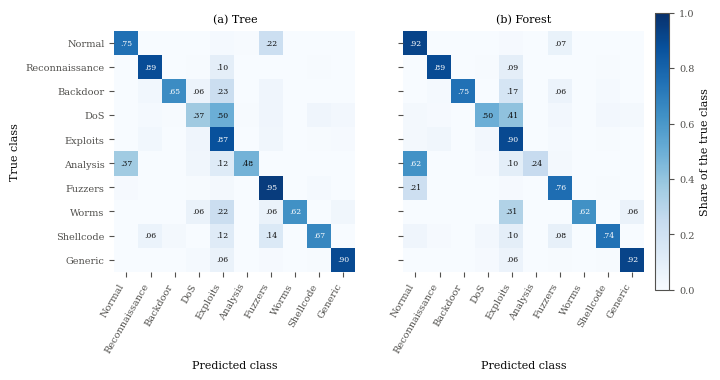

In [ ]:
# figure 6 - confusion matrices for the tree and the forest on the test set
# each row is divided by its total, so a cell is the share of that true class given that prediction
# shares below 0.05 are left blank to keep it readable
fig, axes = plt.subplots(1, 2, figsize=(PAGE_W, 3.6), sharey=True)
for ax, m, letter in zip(axes, ['tree', 'forest'], 'ab'):
    cm = pd.read_csv(RESULTS_DIR + f'confusion_{m}.csv', index_col=0)
    norm = cm.div(cm.sum(axis=1), axis=0)
    im = ax.imshow(norm.values, cmap='Blues', vmin=0, vmax=1)
    for i in range(10):
        for j in range(10):
            v = norm.values[i, j]
            if v >= 0.05:
                ax.text(j, i, f'{v:.2f}'.lstrip('0') if v < 1 else '1.0', ha='center', va='center',
                        fontsize=5.5, color='white' if v > 0.55 else INK)
    ax.set_xticks(range(10)); ax.set_xticklabels(cm.columns, rotation=60, ha='right')
    ax.set_yticks(range(10)); ax.set_yticklabels(cm.index)
    ax.set_xlabel('Predicted class'); ax.set_title(f'({letter}) {NAMES[m]}')
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
axes[0].set_ylabel('True class')
fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02, label='Share of the true class')
save(fig, 'fig6_confusion_matrices')

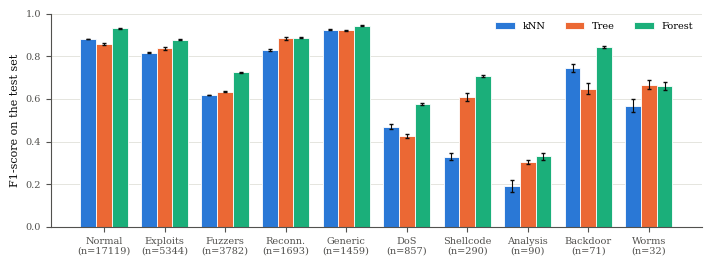

In [2]:
# figure 5 - F1 per class on the test set for the three models, classes ordered by size
# error bars are one standard deviation over the five seeds
pc = pd.read_csv(RESULTS_DIR + 'final_test_per_class.csv', index_col=0)
sd = pd.read_csv(RESULTS_DIR + 'final_test_per_class_sd.csv', header=[0, 1], index_col=0)
pc = pc.sort_values('support', ascending=False)
sd = sd.loc[pc.index]
models = ['knn', 'tree', 'forest']

fig, ax = plt.subplots(figsize=(PAGE_W, 2.7))
x = np.arange(len(pc)); width = 0.26
for i, m in enumerate(models):
    ax.bar(x + (i - 1) * width, sd[(m, 'f1_mean')], width=width, color=COLOURS[m],
           edgecolor='white', linewidth=0.6, label=NAMES[m],
           yerr=sd[(m, 'f1_std')], error_kw={'elinewidth': 0.8, 'capsize': 1.5, 'ecolor': INK})
ax.set_xticks(x)
ax.set_xticklabels([f'{name}\n(n={int(n)})' for name, n in
                    zip(pc.index.str.replace('Reconnaissance', 'Reconn.'), pc['support'])])
ax.set_ylabel('F1-score on the test set'); ax.set_ylim(0, 1)
ax.grid(axis='x', visible=False)
ax.legend(frameon=False, ncol=3, loc='upper right')
fig.tight_layout()
save(fig, 'fig5_per_class_f1')
